# From a trade book to netting-set exposure and XVA

Today's portfolio PV adds trade values. Future credit exposure first adds trade
values **within a legal netting set on each path**, then takes the positive or
negative part. Offsetting trades can therefore reduce exposure. This notebook
compares the same two swaps held together with those swaps held in separate
netting sets. [Setup](../README.md) · [Portfolio PV and risk](../sensitivity/portfolio_risk.ipynb).

`XvaConfig` controls the simulation. Each `NettingSet` carries its own `CsaTerms`
for collateral index/currency and credit/funding inputs. These terms are
separate from the contracts and from the model specification.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market, read_configuration

market = load_market()
ref = market.quotes.reference_date
config_spec = read_configuration(
    "cva",
    "xva.json",
)
config = qs.XvaConfig.from_dict(config_spec)
config_spec


{'model_configs': [{'market_index': 'SOFR',
   'lambda': 0.05,
   'parameter_source': {'Calibrated': {'source': {'Surface': {'market_index': 'SOFR'}},
     'calibration_basket': {'expiries': ['3M', '6M', '1Y', '2Y', '3Y'],
      'strike': 'Atm'}}}}],
 'n_paths': 1024,
 'seed': 42,
 'frequency': 'Quarterly'}

[xva.json](data/xva.json) configures a calibrated SOFR LGM model, 1024 paths,
seed 42, and quarterly exposure dates. The ATM calibration basket contains
3M, 6M, 1Y, 2Y, and 3Y expiries, covering this three-year portfolio. The basket is intentionally limited to the portfolio horizon; extending it requires checking the new ATM strikes against the quoted smile domain. The engine generates future valuations directly.

[credit_curves.json](data/credit_curves.json) bootstraps CORPORATE-A survival
probabilities from the illustrative 1Y, 3Y, and 5Y CDS spreads in
[credit_quotes.json](data/credit_quotes.json). The cell below defines the CSA
conditions directly in Python: this credit index, 40% recovery, and a reusable
`TenorBasedZeroRateTermStructure` of funding spreads over SOFR with 40, 50,
and 60 bp pillars. `ZeroRateTermStructure` can also supply dated pillars;
there is no separate funding-spread curve class. `credit_spread` is a fallback
only; `credit_index` takes precedence. These inputs are illustrative, not live data.

Variation margin is enabled with USD 1,000 receive/post thresholds and USD 500
minimum transfer amount. A threshold is the unsecured amount allowed; MTA is
the minimum absolute change in collateral balance that triggers a transfer.
Calls settle immediately on each simulation date, including the initial date,
and retained collateral accrues at the SOFR remuneration curve. Settlement
lag, margin period of risk, and initial margin are not modeled here.

The receive-fixed and pay-fixed positions share a maturity but differ in
notional. Each hypothetical client receives the same credit and funding terms
so the comparison isolates netting and collateral treatment.


In [2]:
def swap(identifier, notional, side):
    instrument = qs.Swap(
        identifier=identifier,
        start_date=ref,
        maturity_date=ref + "3Y",
        notional=notional,
        fixed_rate=0.045,
        currency=qs.Currency.USD,
        market_index=qs.MarketIndex.SOFR,
    )
    return qs.Trade(instrument, ref, side)


receive = swap("RECEIVE", 1_000_000, qs.Side.LongReceive)
pay = swap("PAY", 800_000, qs.Side.PayShort)
funding_curve = qs.TenorBasedZeroRateTermStructure(
    reference_date=ref,
    tenors=["0D", "1Y", "3Y"],
    rates=[0.004, 0.005, 0.006],
    day_counter=qs.DayCounter.Actual365,
    compounding=qs.Compounding.Continuous,
    interpolator="Linear",
    enable_extrapolation=True,
)
csa = qs.CsaTerms(
    collateral_index=qs.MarketIndex.SOFR,
    collateral_currency=qs.Currency.USD,
    credit_index=qs.MarketIndex.credit("CORPORATE-A"),
    credit_spread=0.01,
    recovery=0.4,
    funding_spread_curve=funding_curve,
    counterparty_threshold=1_000.0,
    own_threshold=1_000.0,
    minimum_transfer_amount=500.0,
    variation_margin=True,
)


def run_exposure(netting_sets):
    with qs.PricingContext(
        quotes=market.quotes,
        curves=market.curves,
        credit_curves=market.credit_curves,
        csa_policy=market.csa_policy,
        volatility_surfaces=market.volatility_surfaces,
    ) as context:
        return context.run_xva(config, netting_sets=netting_sets)


netted = run_exposure([qs.NettingSet("ONE-CLIENT", [receive, pay], csa)])
separate = run_exposure([
    qs.NettingSet("CLIENT-A", [receive], csa),
    qs.NettingSet("CLIENT-B", [pay], csa),
])
netted.xva_values

,netting_set,measure,value
0,ONE-CLIENT,CVA,14.933653
1,ONE-CLIENT,FVA,3.486952


## Retrieve the three result views

`xva_values` is a table keyed by netting set and measure. `exposures` is a list
of profiles; select them by `netting_set`, rather than assuming list order.
`sensitivities` is the XVA parameter-risk table, separate from today's trade
PV sensitivities. The credit snapshot retains numerical survival pillars,
then creates independent differentiation leaves: `CVA.Cds_...` rows measure
$\partial XVA/\partial S(t_j)$, **not** CDS-spread quote risk despite their
quote-like labels. The credit bootstrap Jacobian is not replayed here.
Funding rows similarly measure derived spread-pillar risk, not a replay of
the source funding curve's calibration. Here the dated funding spreads are
supplied directly, so their coordinates are annual decimal spreads.

The reported EPE, ENE, and EE are **raw, pre-margin** netting-set exposures.
XVA aggregators instead consume each path's exposure after variation margin.
Consequently changing CSA thresholds can change XVA without changing these
raw profiles.

EPE is the expected positive value at each date, ENE is the expected negative
value **with a negative sign**, and EE is the signed mean, so `EE = EPE + ENE`.
EPE here is a date profile, not a single time-averaged scalar. The Python result
exposes these summaries, not the full pathwise NPV cube or PFE percentiles.

In [3]:
netted_profiles = {
    profile.netting_set: profile.to_dataframe().set_index("date")
    for profile in netted.exposures
}
separate_profiles = {
    profile.netting_set: profile.to_dataframe().set_index("date")
    for profile in separate.exposures
}
profile = netted_profiles["ONE-CLIENT"]
separate_total = separate_profiles["CLIENT-A"] + separate_profiles["CLIENT-B"]
profile.head(8)


,epe,ene,ee
date,,,
2026-02-24,1560.219484,0.000000,1560.219484
2026-05-24,2670.463071,-1102.076618,1568.386453
2026-08-24,3161.865586,-1317.550417,1844.315169
2026-11-24,3654.875072,-1824.342032,1830.533040
2027-02-24,3602.488961,-1488.065787,2114.423173
2027-05-24,3907.705731,-1808.613020,2099.092711
2027-08-24,3151.837395,-1343.436832,1808.400563
2027-11-24,3279.948042,-1500.874528,1779.073515


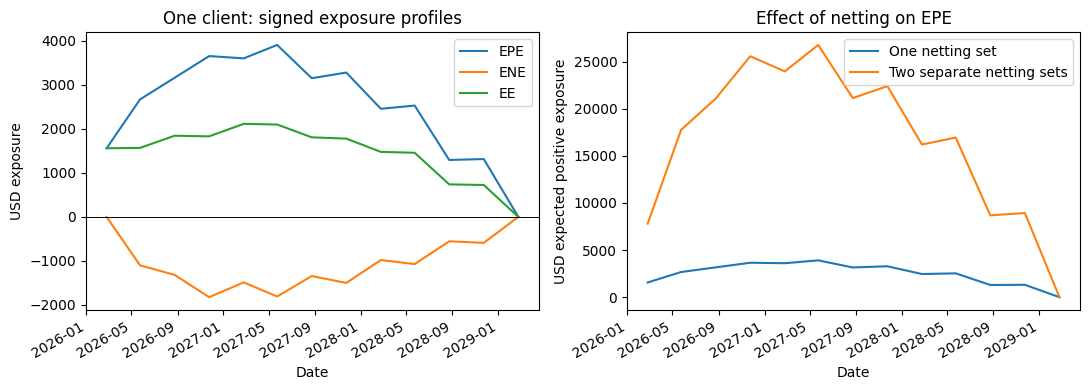

In [4]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4),
)
dates = pd.to_datetime(profile.index)
for measure in ["epe", "ene", "ee"]:
    axes[0].plot(
        dates,
        profile[measure],
        label=measure.upper(),
    )
axes[0].set(
    title="One client: signed exposure profiles",
    xlabel="Date",
    ylabel="USD exposure",
)
axes[0].axhline(
    0,
    color="black",
    linewidth=0.7,
)
axes[0].legend()
axes[1].plot(
    dates,
    profile["epe"],
    label="One netting set",
)
axes[1].plot(
    dates,
    separate_total["epe"],
    label="Two separate netting sets",
)
axes[1].set(
    title="Effect of netting on EPE",
    xlabel="Date",
    ylabel="USD expected positive exposure",
)
axes[1].legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


The swaps offset before the positive-part operation when they are in one
netting set. In separate sets, exposure to one client cannot be reduced by a
liability to another. Collateral balances and thresholds are applied separately
per legal set.

The table compares grouping with variation margin enabled, then disables
margin for the same netted portfolio while retaining identical credit,
funding, and model inputs. Preserve the engine's measure labels and sign
conventions in downstream reporting. Survival probabilities, recovery, funding spreads,
and market quotes have different sensitivity units; thresholds and MTA are
amounts, not rates.

In [5]:
unmargined_csa = qs.CsaTerms(
    collateral_index=csa.collateral_index,
    collateral_currency=csa.collateral_currency,
    credit_index=csa.credit_index,
    credit_spread=csa.credit_spread,
    recovery=csa.recovery,
    funding_spread_curve=csa.funding_spread_curve,
    counterparty_threshold=csa.counterparty_threshold,
    own_threshold=csa.own_threshold,
    minimum_transfer_amount=csa.minimum_transfer_amount,
    variation_margin=False,
)
unmargined = run_exposure([
    qs.NettingSet("ONE-CLIENT", [receive, pay], unmargined_csa),
])
comparison = pd.concat(
    {
        "one set, margin on": netted.xva_values.groupby("measure")["value"].sum(),
        "separate sets, margin on": separate.xva_values.groupby("measure")["value"].sum(),
        "one set, margin off": unmargined.xva_values.groupby("measure")["value"].sum(),
    },
    axis=1,
)
comparison

,"one set, margin on","separate sets, margin on","one set, margin off"
measure,,,
CVA,14.933653,24.859129,70.732865
FVA,3.486952,0.008304,20.850144


In [6]:
parameter_risk = netted.sensitivities.copy()

def risk_coordinate(parameter):
    if ".CVA.Cds_" in parameter:
        return "survival probability (not CDS spread)"
    if parameter.endswith(".CVA.recovery"):
        return "recovery fraction"
    if ".FVA.funding_spread." in parameter:
        return "annual decimal funding spread"
    return "market quote (native units)"

parameter_risk["risk_coordinate"] = parameter_risk["parameter"].map(risk_coordinate)
parameter_risk.sort_values(
    "value",
    key=lambda series: series.abs(),
    ascending=False,
).head(12)


,parameter,value,risk_coordinate
10,OIS_USD_SOFR_3Y,-1795.063566,market quote (native units)
8,OIS_USD_SOFR_2Y,817.163391,market quote (native units)
18,ONE-CLIENT.FVA.funding_spread.2027-02-24,374.603166,annual decimal funding spread
14,ONE-CLIENT.CVA.Cds_CORPORATE-A_USD_3Y,-283.167257,survival probability (not CDS spread)
19,ONE-CLIENT.FVA.funding_spread.2029-02-24,204.096488,annual decimal funding spread
7,OIS_USD_SOFR_1Y,154.185460,market quote (native units)
17,ONE-CLIENT.FVA.funding_spread.2026-02-24,97.339413,annual decimal funding spread
13,ONE-CLIENT.CVA.Cds_CORPORATE-A_USD_1Y,-64.812584,survival probability (not CDS spread)
16,ONE-CLIENT.CVA.recovery,-24.889421,recovery fraction
2,CapletFloorlet_USD_SOFR_3M_3M_Absolute_0.035_S...,-8.880348,market quote (native units)


## Equations, signs, and checks on the exposure experiment

For raw netting-set value $V_{p,i}$ on path $p$ and date $i$:
$$EPE_i=E[\max(V_{p,i},0)],\quad
ENE_i=E[\min(V_{p,i},0)],\quad EE_i=EPE_i+ENE_i.$$
ENE is nonpositive. These are pointwise profiles, not time-averaged EPE or PFE
quantiles. Let $\widetilde V$ be path value after variation margin. In this
independent-credit approximation, the engine's discretizations are
$$CVA=(1-R)\sum_i D_iE[\max(\widetilde V_i,0)]
       [S(t_{i-1})-S(t_i)],$$
$$FVA=\sum_iD_iE[\widetilde V_i]\,s_i\,\Delta t_i.$$
FVA uses **signed** exposure and right-endpoint Actual/365 intervals. CVA is
reported as a positive loss amount; do not automatically add it to a clean PV.
The high-level run constructs CVA/FVA factories, not a bilateral DVA study.
The credit-curve input takes precedence over the flat credit-spread fallback;
only that fallback uses $\lambda=s_{\rm credit}/(1-R)$.

Legal netting reduces the sum of raw positive parts pathwise. It need not
monotonically reduce signed FVA, especially when collateral thresholds and
transfer rules are applied separately in each set. Correlated default/rates,
wrong-way risk, margin lag and initial margin are outside this experiment.


In [7]:
import numpy as np

for frame in [profile, *separate_profiles.values()]:
    assert frame["epe"].ge(-1e-10).all()
    assert frame["ene"].le(1e-10).all()
    assert np.allclose(frame["ee"], frame["epe"] + frame["ene"], atol=1e-8, rtol=1e-10)
assert (profile["epe"] <= separate_total["epe"] + 1e-8).all()
assert np.allclose(profile["ee"], separate_total["ee"], atol=1e-7, rtol=1e-10)
unmargined_profile = next(
    item.to_dataframe().set_index("date") for item in unmargined.exposures
    if item.netting_set == "ONE-CLIENT"
)
assert np.allclose(profile, unmargined_profile, atol=1e-8, rtol=1e-10)
assert comparison.loc["CVA", "one set, margin on"] <= comparison.loc["CVA", "one set, margin off"] + 1e-8
assert set(netted.xva_values["measure"]) == {"CVA", "FVA"}
print(f"Maximum raw EPE: netted USD {profile['epe'].max():,.2f}; separate USD {separate_total['epe'].max():,.2f}.")
print(f"Netted CVA: margin on USD {comparison.loc['CVA', 'one set, margin on']:.4f}; off USD {comparison.loc['CVA', 'one set, margin off']:.4f}.")
print("Raw profiles are unchanged by margin; the adjustment changes because it uses post-margin paths.")
comparison


Maximum raw EPE: netted USD 3,907.71; separate USD 26,772.98.
Netted CVA: margin on USD 14.9337; off USD 70.7329.
Raw profiles are unchanged by margin; the adjustment changes because it uses post-margin paths.


,"one set, margin on","separate sets, margin on","one set, margin off"
measure,,,
CVA,14.933653,24.859129,70.732865
FVA,3.486952,0.008304,20.850144


## Conclusion

Offsetting contracts reduce raw positive exposure when they belong to one
legal set. Immediate variation margin reduces CVA in this example without
changing the returned raw profiles. Signed FVA behaves differently: separate
collateral accounts can change cancellation of positive and negative funding
needs. The identical seed makes comparisons controlled; path/grid/seed
refinement is still needed before interpreting numerical precision.


Increase path count and refine the exposure grid in the configuration to study
stability. Changing the seed helps reveal sampling variation. This example
isolates one-currency rate exposure; it does not establish the adequacy of a
model, calibration basket, or credit/funding assumption for another portfolio.